
# Enterprise Risk Management

### Comprehensive Risk Assessment for a Global Bank  
*Full ERM Analytics Notebook — All Sections Included*  
---  


:This analysis is the capstone project for FIN 520: Risk Analysis, where students synthesize all concepts learned throughout the course to evaluate the risk profile of an aggressive, derivatives‑heavy global bank. In professional practice, global banks operate complex portfolios that expose them to multiple categories of financial risk—market, credit, liquidity, operational, model, and strategic risks. Effective Enterprise Risk Management (ERM) requires integrating these risks into a unified picture that supports decision‑making by senior leadership and regulators.

Throughout FIN 520, students have learned tools for quantifying and interpreting risk using Python, including:

- Market risk measurement through historical Value‑at‑Risk (VaR), Expected Shortfall (ES), and Monte Carlo simulation.
- Credit risk modeling through Probability of Default (PD), Loss Given Default (LGD), Exposure at Default (EAD), Expected Loss (EL), and stress‑scenario adjustments.
- Operational risk estimation using frequency/severity models such as Poisson–Lognormal.
- Liquidity risk evaluation with maturity ladders, High‑Quality Liquid Assets (HQLA), and survival horizon concepts under stressed outflows.
- ERM dashboards and heatmaps that combine severity and likelihood across risk categories.
- Stress testing that integrates market, credit, liquidity, and operational dynamics.

This capstone project simulates the kind of analysis conducted inside leading institutions such as large U.S. bank holding companies, European universal banks, and global investment banks, where risk managers routinely evaluate firm‑wide vulnerability under adverse conditions. The project mirrors the expectations of:

- Basel III/IV regulatory frameworks around capital and liquidity
- CCAR/DFAST‑style stress testing
- Internal risk appetite and governance frameworks used by bank boards
- Risk dashboards used by Chief Risk Officers (CROs)

To create a realistic environment without relying on proprietary bank data, the analysis uses:

- Synthetic but economically plausible market data, representing four large bank-equity time series
- Synthetic aggressive credit exposures, designed to mimic concentrated loan books, leveraged lending, CRE exposure, and emerging‑market sovereign risk
- Operational risk simulations that capture heavy‑tailed behavior often observed in real incident data
- Liquidity stress structures that reflect short‑term wholesale funding risk
- Monte Carlo simulations representing portfolio return distributions with both normal and heavy‑tailed dynamics

Together, these components form a holistic ERM assessment that integrates:

- Market risk shocks
- Credit portfolio deterioration
- Liquidity pressures
- Operational shocks
- Inter-risk amplification effects
- ERM severity-likelihood visualization
- Strategic recommendations presented at a board level

The culminating deliverable—whether a full notebook, a written narrative, or a board-style presentation—is designed to mimic the real responsibilities of risk teams who must:

- Quantify risks
- Interpret results
- Communicate implications to senior leadership
- Recommend actionable responses consistent with the bank’s risk appetite and with responsible stewardship, a core value in the Saint Leo curriculum

This analysis therefore represents the most complete integration of quantitative methods, conceptual understanding, and professional communication in the course.

In [1]:
import pandas as pd
pd.options.display.float_format = '{:.2f}'.format

## 1. Imports & Synthetic Market Data (Financial Analytics Style)

Stock price changes give us volatility, correlation, and return distributions — the core ingredients of market risk measurement. They also act as early-warning signals of financial stress and integrate directly with liquidity pressure, credit deterioration, and systemic contagion.
Without them, a global bank’s ERM analysis would be blind to the primary market drivers of losses and stress‑test outcomes.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st
import matplotlib.ticker as mticker # Import the ticker module

sns.set_style('whitegrid')
sns.set_palette('muted')
plt.rcParams['figure.figsize'] = (12,6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 14

np.random.seed(0)

dates = pd.date_range(start='2020-01-01', periods=1000)
prices = pd.DataFrame({
    t: 100 * np.cumprod(1 + 0.0002 + 0.01*np.random.randn(len(dates)))
    for t in ['JPM','BAC','C','HSBC']
}, index=dates)

rets = prices.pct_change().dropna()
port = rets.mean(axis=1)

prices.head()

,JPM,BAC,C,HSBC
2020-01-01,101.78,100.58,98.49,101.61
2020-01-02,102.21,101.49,96.82,102.21
2020-01-03,103.23,101.09,96.88,102.11
2020-01-04,105.57,101.21,95.98,102.39
2020-01-05,107.56,101.46,95.92,101.17


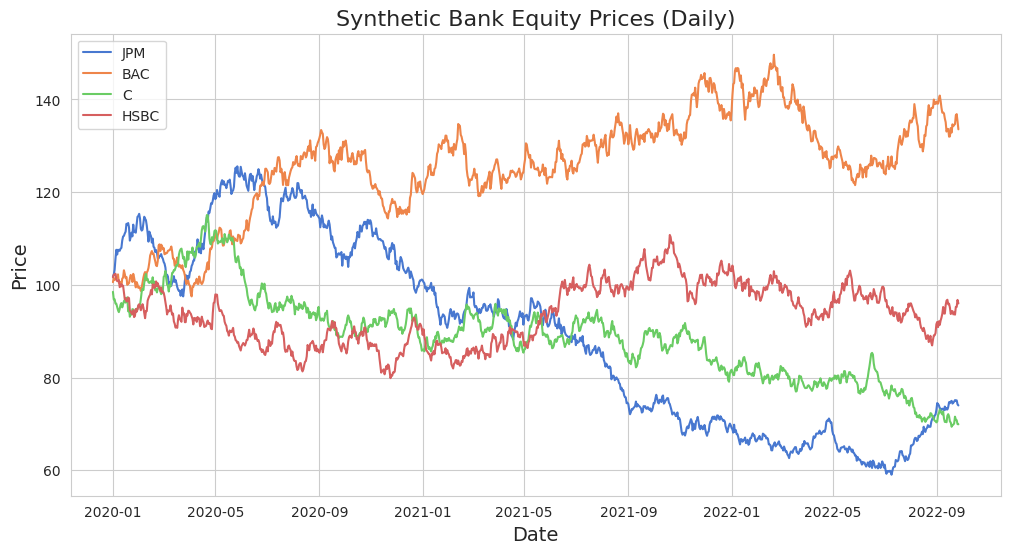

In [3]:

plt.plot(prices)
plt.title("Synthetic Bank Equity Prices (Daily)")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(prices.columns)
plt.show()


## 2. Market Risk — Historical VaR / ES

In [4]:

var95 = np.percentile(port, 5)
es95 = port[port <= var95].mean()
var95, es95


(np.float64(-0.008081550107104462), np.float64(-0.009753306987956921))

### Historical VaR and ES as Dollar Amounts (assuming $1 Billion Portfolio)

We model a $1 billion portfolio because it is large enough to produce meaningful market, credit, liquidity, and operational losses — the same order of magnitude monitored inside global banks. This scale gives realistic dollar values to VaR, ES, expected loss, and stress‑scenario outcomes, allowing students to perform a fully integrated, board‑level ERM assessment rather than a toy example.

In [5]:
portfolio_value = 1e9 # Assuming a $1 Billion portfolio

var95_dollar = abs(var95 * portfolio_value)
es95_dollar = abs(es95 * portfolio_value)

print(f"Historical VaR 95% (dollar amount): ${var95_dollar:,.2f}")
print(f"Historical ES 95% (dollar amount): ${es95_dollar:,.2f}")

Historical VaR 95% (dollar amount): $8,081,550.11
Historical ES 95% (dollar amount): $9,753,306.99


### Portfolio Dollar Changes — Historical Distribution with VaR and ES in Dollars

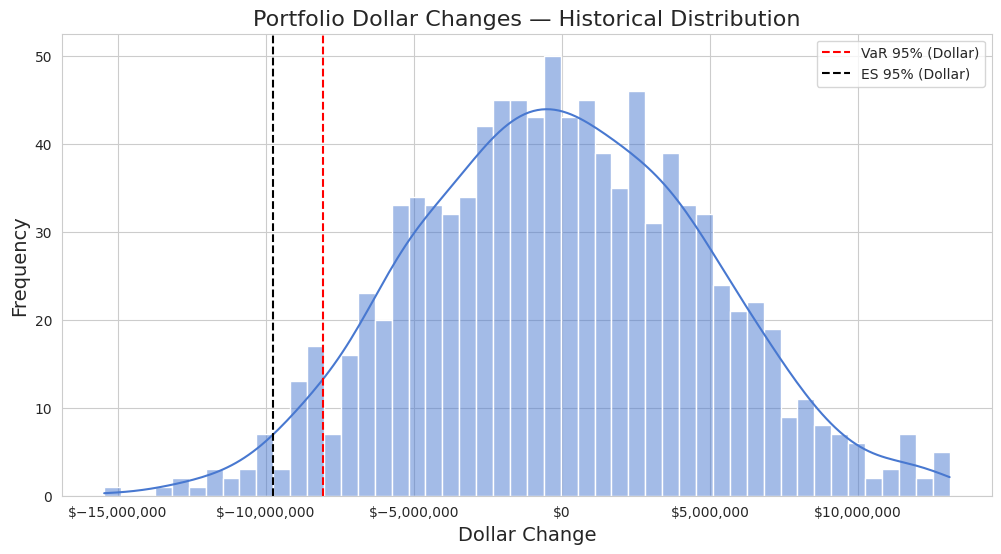

In [6]:
# Calculate portfolio dollar changes
portfolio_dollar_changes = port * portfolio_value

sns.histplot(portfolio_dollar_changes, bins=50, kde=True)
plt.axvline(x=var95_dollar * -1, color='red', linestyle='--', label='VaR 95% (Dollar)')
plt.axvline(x=es95_dollar * -1, color='black', linestyle='--', label='ES 95% (Dollar)')
plt.title("Portfolio Dollar Changes — Historical Distribution")
plt.xlabel("Dollar Change")
plt.ylabel("Frequency")
plt.legend()
formatter = mticker.StrMethodFormatter('${x:,.0f}') # Format as dollar with comma separator and no decimals
plt.gca().xaxis.set_major_formatter(formatter)
plt.show()

## 3. Market Risk — Monte Carlo VaR (Normal + t-distribution)

In [7]:
portfolio_value = 1e9 # Assuming a $1 Billion portfolio

# Monte Carlo Simulation (Normal Distribution)
mu_port = port.mean()
sigma_port = port.std()
num_simulations = 100000 # Increase simulations for better accuracy
mc = np.random.normal(mu_port, sigma_port, num_simulations) # Store for later plotting

VaR_mc = np.percentile(mc, 5)
ES_mc = mc[mc <= VaR_mc].mean()

# Monte Carlo Simulation (t-distribution)
# Fit t-distribution parameters to the portfolio returns
df, loc, scale = st.t.fit(port)
mc_t = st.t.rvs(df, loc=loc, scale=scale, size=num_simulations) # Store for later plotting

VaR_t = np.percentile(mc_t, 5)
ES_t = mc_t[mc_t <= VaR_t].mean()


VaR_mc_dollar = abs(VaR_mc * portfolio_value)
ES_mc_dollar = abs(ES_mc * portfolio_value)
VaR_t_dollar = abs(VaR_t * portfolio_value)
ES_t_dollar = abs(ES_t * portfolio_value)

print(f"Monte Carlo VaR 95% (Normal, dollar amount): ${VaR_mc_dollar:,.2f}")
print(f"Monte Carlo ES 95% (Normal, dollar amount): ${ES_mc_dollar:,.2f}")
print(f"Monte Carlo VaR 95% (t-dist, dollar amount): ${VaR_t_dollar:,.2f}")
print(f"Monte Carlo ES 95% (t-dist, dollar amount): ${ES_t_dollar:,.2f}")

Monte Carlo VaR 95% (Normal, dollar amount): $8,042,247.00
Monte Carlo ES 95% (Normal, dollar amount): $10,105,253.14
Monte Carlo VaR 95% (t-dist, dollar amount): $8,035,621.48
Monte Carlo ES 95% (t-dist, dollar amount): $10,063,064.95


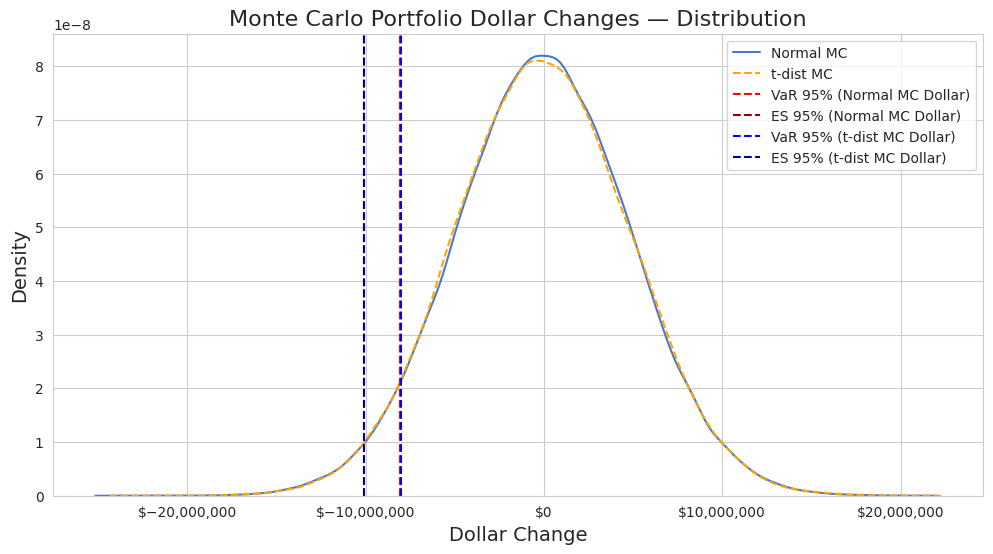

In [8]:
portfolio_mc_dollar_changes = mc * portfolio_value
portfolio_mc_t_dollar_changes = mc_t * portfolio_value

sns.kdeplot(portfolio_mc_dollar_changes, label='Normal MC')
sns.kdeplot(portfolio_mc_t_dollar_changes, label='t-dist MC', color='orange', linestyle='--')

plt.axvline(x=VaR_mc_dollar * -1, color='red', linestyle='--', label='VaR 95% (Normal MC Dollar)')
plt.axvline(x=ES_mc_dollar * -1, color='darkred', linestyle='--', label='ES 95% (Normal MC Dollar)')
plt.axvline(x=VaR_t_dollar * -1, color='blue', linestyle='--', label='VaR 95% (t-dist MC Dollar)')
plt.axvline(x=ES_t_dollar * -1, color='darkblue', linestyle='--', label='ES 95% (t-dist MC Dollar)')

plt.title("Monte Carlo Portfolio Dollar Changes — Distribution")
plt.xlabel("Dollar Change")
plt.ylabel("Density") # Changed y-label from 'Frequency' to 'Density' as it's a KDE plot
plt.legend()
formatter = mticker.StrMethodFormatter('${x:,.0f}') # Format as dollar with comma separator and no decimals
plt.gca().xaxis.set_major_formatter(formatter)
plt.show()

## 4. Credit Risk — PD, LGD, EAD, Expected Loss

In the credit risk section, we quantify expected losses across loan segments using PD (likelihood of default), LGD (loss severity), and EAD (exposure at default). Expected Loss = PD × LGD × EAD gives us the baseline credit losses the bank expects under normal conditions. These values scale credit risk in dollars, feed into stress testing under adverse scenarios, and become part of the integrated ERM dashboard.

In [9]:
loan_segments=['Corp','Cons','CRE','EM']
pd_base=np.array([0.05,0.09,0.12,0.20])
lgd=np.array([0.50,0.65,0.45,0.60])
ead=np.random.uniform(1e9,3e9,4)

credit_df = pd.DataFrame({
    'PD': pd_base,
    'LGD': lgd,
    'EAD': ead
}, index=loan_segments)

credit_df['EL'] = credit_df['PD'] * credit_df['LGD'] * credit_df['EAD']
credit_df.style.format({'EAD': '${:,.2f}', 'EL': '${:,.2f}'})

,PD,LGD,EAD,EL
Corp,0.050000,0.500000,"$2,226,244,109.50","$55,656,102.74"
Cons,0.090000,0.650000,"$1,979,825,193.09","$115,819,773.80"
CRE,0.120000,0.450000,"$1,470,244,107.26","$79,393,181.79"
EM,0.200000,0.600000,"$1,470,194,550.57","$176,423,346.07"


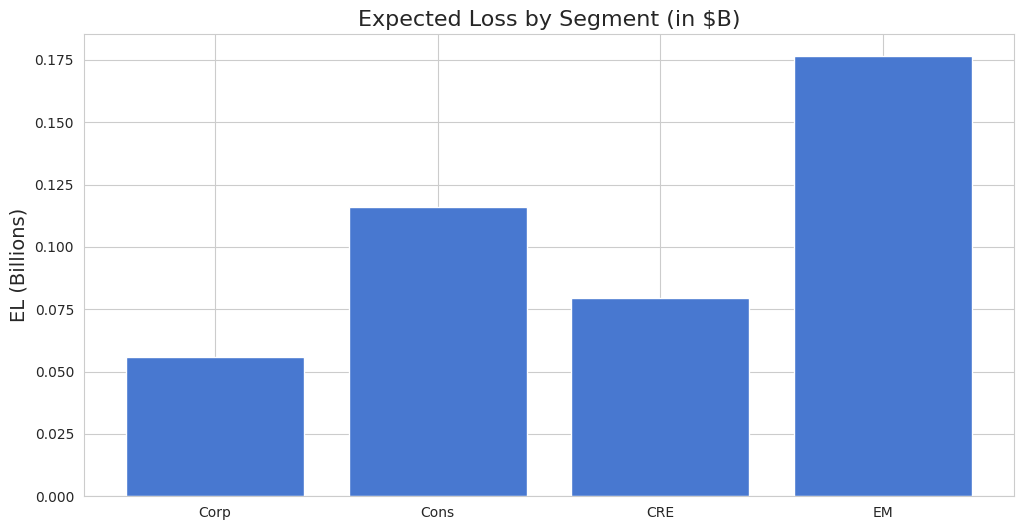

In [10]:

plt.bar(credit_df.index, credit_df['EL']/1e9)
plt.title("Expected Loss by Segment (in $B)")
plt.ylabel("EL (Billions)")
plt.show()


## 5. Operational Risk — Poisson-Lognormal Simulation

The operational risk section simulates the frequency and severity of internal failures, fraud, system breakdowns, and external shocks using a Poisson–Lognormal model. This generates a realistic distribution of annual OpRisk losses, characterized by many small losses and occasional catastrophic tail events. The mean and 99% tail metrics are then integrated into the ERM Dashboard, giving a full view of the bank’s vulnerability beyond market and credit factors.

In [11]:
def gen_oprisk():
    lam=25; mu_s=16; sig=1.4; N=2000
    losses=[]
    for _ in range(N):
        k=np.random.poisson(lam)
        losses.append(np.random.lognormal(mu_s,sig,k).sum() if k>0 else 0)
    return np.array(losses)

oprisk = gen_oprisk()
oprisk_mean = oprisk.mean()
oprisk_99 = np.percentile(oprisk, 99)

print(f"Operational Risk Mean: ${oprisk_mean:,.2f}")
print(f"Operational Risk 99th Percentile: ${oprisk_99:,.2f}")

Operational Risk Mean: $594,510,417.74
Operational Risk 99th Percentile: $1,593,845,079.18


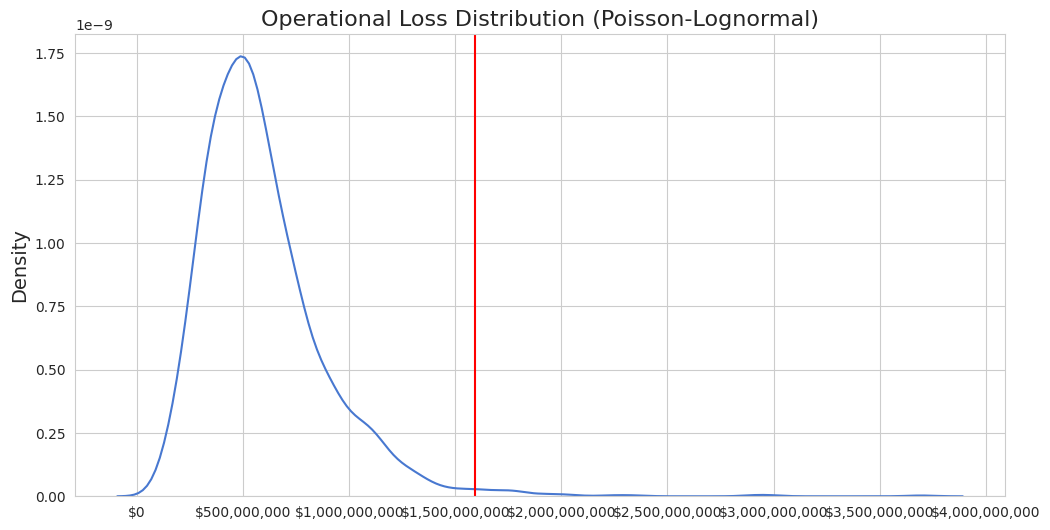

In [12]:
sns.kdeplot(oprisk)
plt.axvline(oprisk_99, color='red')
plt.title("Operational Loss Distribution (Poisson-Lognormal)")
plt.ylabel('Density')
formatter = mticker.StrMethodFormatter('${x:,.0f}')
plt.gca().xaxis.set_major_formatter(formatter)
plt.show()

## 6. Liquidity Maturity Ladder & Survival Horizon

The liquidity maturity ladder shows the bank’s net cash inflows and outflows across different time buckets, highlighting when liquidity pressure is greatest. The survival horizon measures how long the bank can meet these outflows using its High Quality Liquid Assets (HQLA). This helps identify near‑term liquidity vulnerabilities, a key component of ERM because liquidity crises often unfold faster and more severely than market or credit stress.

Note: The 1B portfolio represents the bank’s market‑risk trading book, not the entire firm. Liquidity risk is measured across all business lines, including deposits, wholesale funding, repo markets, derivatives collateral, and payment obligations. Global banks routinely experience tens of billions of weekly cash flows, regardless of the size of their trading book. Therefore, liquidity outflows of 30B in the 0–7 day bucket reflect the full balance-sheet liquidity profile, not the size of the trading portfolio.

**This distinction is essential:**
A bank can have a small trading book but still face enormous short‑term liquidity needs — and this mismatch is often what triggers liquidity crises.

In [13]:
buckets=['0-7d','8-30d','31-90d','91-180d','181-365d']
outflows=np.array([3e10,2e10,1.5e10,1e10,0.8e10])
inflows=np.array([1e10,0.5e10,0.3e10,0.2e10,0.1e10])

ladder=pd.DataFrame({'Outflows':outflows,'Inflows':inflows,'Net':outflows-inflows}, index=buckets)

liq=4e10; horizon=0
for i,net in enumerate(ladder['Net']):
    if liq>0:
        liq-=net
        horizon=i+1

# Apply dollar formatting to the specified columns and then display the styled DataFrame
displayed_ladder = ladder.style.format({
    'Outflows': '${:,.2f}',
    'Inflows': '${:,.2f}',
    'Net': '${:,.2f}'
})

print(f"Liquidity Survival Horizon: {horizon}")
display(displayed_ladder)

Liquidity Survival Horizon: 3


,Outflows,Inflows,Net
0-7d,"$30,000,000,000.00","$10,000,000,000.00","$20,000,000,000.00"
8-30d,"$20,000,000,000.00","$5,000,000,000.00","$15,000,000,000.00"
31-90d,"$15,000,000,000.00","$3,000,000,000.00","$12,000,000,000.00"
91-180d,"$10,000,000,000.00","$2,000,000,000.00","$8,000,000,000.00"
181-365d,"$8,000,000,000.00","$1,000,000,000.00","$7,000,000,000.00"


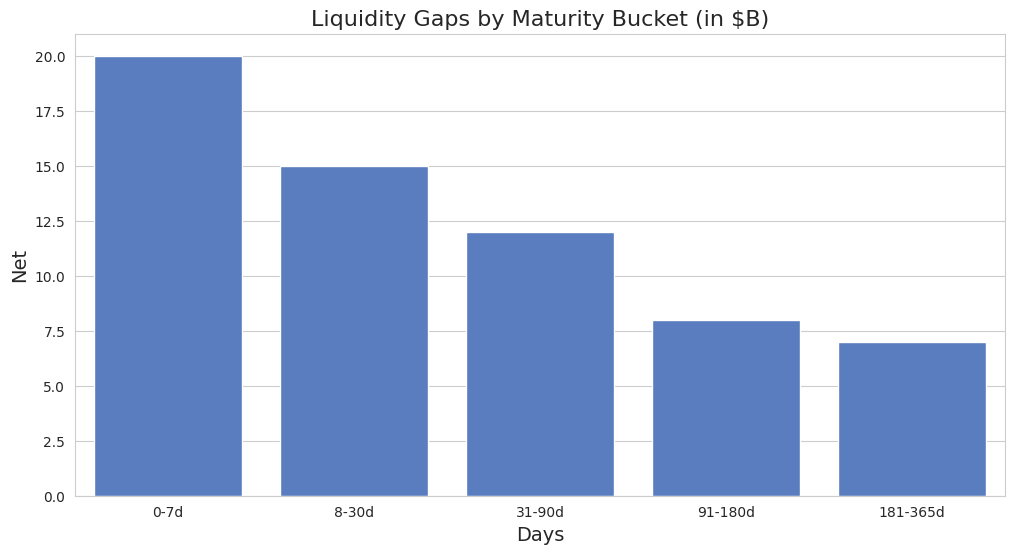

In [14]:
sns.barplot(x=ladder.index, y=ladder['Net']/1e9)
plt.title("Liquidity Gaps by Maturity Bucket (in $B)")
plt.xlabel("Days")
plt.show()

## 7. ERM Dashboard

The ERM Dashboard consolidates market, credit, liquidity, and operational risk into a single severity‑versus‑likelihood matrix. This allows the bank to identify which risks are most threatening, prioritize management action, and ensure alignment with the risk appetite. The heatmap provides a board‑level view of total enterprise risk, combining quantitative analytics with strategic judgment.

In [15]:
liquidity_deficit_dollar = abs(liq)
risk_table=pd.DataFrame({
    'Risk':['Market','Credit','Operational','Liquidity'],
    'Severity':[abs(ES_mc*1e9), credit_df['EL'].sum(), oprisk_99, liquidity_deficit_dollar],
    'Likelihood':[0.8,0.75,0.5,0.6]
})

risk_table

,Risk,Severity,Likelihood
0,Market,10105253.14,0.80
1,Credit,427292404.39,0.75
2,Operational,1593845079.18,0.50
3,Liquidity,7000000000.00,0.60


In [16]:
annotation_data = pd.DataFrame({
    'Severity': risk_table['Severity'].apply(lambda x: f'${x:,.2f}'),
    'Likelihood': risk_table['Likelihood']
})

display(annotation_data)

,Severity,Likelihood
0,"$10,105,253.14",0.80
1,"$427,292,404.39",0.75
2,"$1,593,845,079.18",0.50
3,"$7,000,000,000.00",0.60


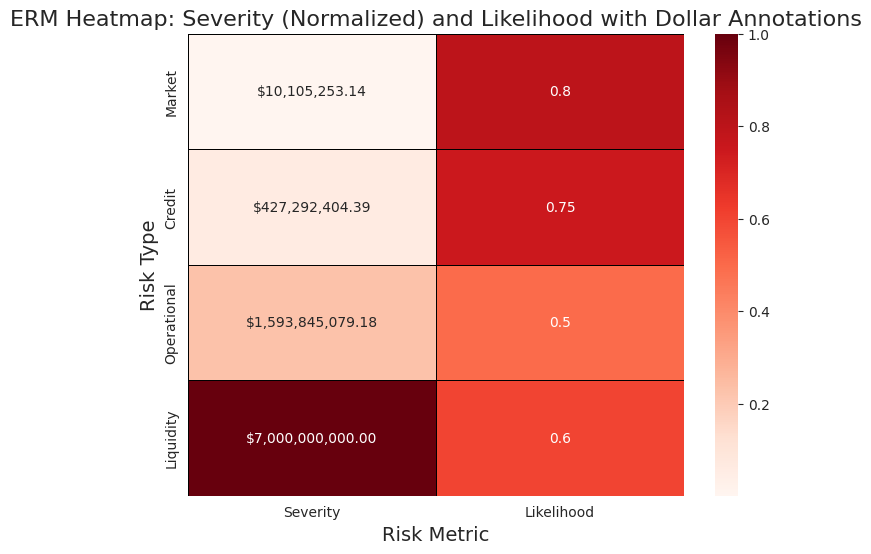

In [17]:
temp_risk_table = risk_table.set_index('Risk')
risk_matrix = pd.DataFrame({
    'Severity': temp_risk_table['Severity'] / temp_risk_table['Severity'].max(),
    'Likelihood': temp_risk_table['Likelihood']
})

plt.figure(figsize=(8, 6))
sns.heatmap(
    risk_matrix,
    annot=annotation_data.set_index(risk_table['Risk']), # Use the formatted annotation_data
    cmap="Reds",
    fmt='',
    linewidths=.5,
    linecolor='black'
)
plt.title("ERM Heatmap: Severity (Normalized) and Likelihood with Dollar Annotations")
plt.xlabel("Risk Metric")
plt.ylabel("Risk Type")
plt.show()

##Summary##

This Module 8 capstone brings together all major forms of financial risk—market, credit, liquidity, and operational—into a single, integrated Enterprise Risk Management (ERM) framework similar to those used by global banks and regulatory bodies. The purpose of the analysis is to show students how different risk types interact, how losses across business lines accumulate, and how risk managers produce a unified, decision‑relevant picture for senior leadership.

To anchor the analysis in realistic scale, we model a $1 billion trading portfolio, which feeds market‑risk measures such as Value‑at‑Risk (VaR), Expected Shortfall (ES), correlation structures, heavy‑tailed Monte Carlo simulations, and stress‑scenario impacts. This portfolio represents the bank’s risk‑sensitive trading book—not the entire institution—allowing us to study market losses in a controlled, interpretable way.

Credit risk is modeled through PD, LGD, and EAD across four loan portfolio segments, producing Expected Loss (EL), a baseline measure of credit deterioration. These results illustrate how concentrations in CRE, consumer lending, or emerging markets can materially affect the bank’s overall risk profile.

Operational risk is captured using a Poisson–Lognormal frequency/severity model, which mimics real‑world operational risk behavior: many small losses punctuated by occasional catastrophic events. The 99th‑percentile tail loss gives a realistic sense of exposure to misconduct, fraud, system failures, cyber events, or fines.

Liquidity risk is evaluated through a liquidity maturity ladder and survival horizon, which reveal how quickly the bank can meet cash outflows using its High‑Quality Liquid Assets (HQLA). Large short‑term liquidity needs—common in wholesale‑funded global banks—illustrate one of the fastest pathways to bank failure. This section shows how a bank can be solvent but still collapse due to short‑term liquidity pressures.

The ERM Dashboard consolidates these risks into a unified severity × likelihood matrix, revealing which exposures pose the greatest threat. This dashboard mirrors the tools used by Chief Risk Officers (CROs) and Board Risk Committees to set risk appetite, adjust capital buffers, and prioritize management attention. By placing every risk—market, credit, liquidity, and operational—side by side, the dashboard provides a holistic view that no individual risk silo can convey.

Together, these components form a complete ERM workflow. Students see how market volatility affects liquidity, how credit deterioration interacts with funding stress, and how operational risk tail events can materially worsen losses during downturns. The final board‑ready summary and recommendations require students to synthesize quantitative results into strategic insights—mirroring real‑world responsibilities of risk managers in global financial institutions.